In [65]:
import os 
import numpy as np 
import pandas as  pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')

from sklearn.metrics import confusion_matrix,classification_report

import tensorflow  as tf 
from tensorflow import keras 
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers 
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, BatchNormalization, Dense, Input, Flatten, ReLU

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dropout,
    BatchNormalization,
    Dense,
    Input,
    Flatten
)

from tensorflow.keras.utils import image_dataset_from_directory

from tensorflow.keras.applications import EfficientNetB0, ResNet50

In [3]:
%pip install tensorflow

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 1.0/384.1 MB 3.9 MB/s eta 0:01:39
   ---------------------------------------- 2.9/384.1 MB 5.9 MB/s eta 0:01:05
   ---------------------------------------- 4.2/384.1 MB 6.2 MB/s eta 0:01:02
    --------------------------------------- 6.3/384.1 MB 7.1 MB/s eta 0:00:54
    --------------------------------------- 7.9/384.1 MB 7.2 MB/s eta 0:00:52
   - -------------------------------------- 10.2/384.1 MB 7.8 MB/s eta 0:00:48
   - -------------------------------------- 11.8/384.1 MB 7.8 MB/s eta 0:00:48
   - -------------------------------------- 12.8/384.1 MB 7.5 MB/s eta 0:00:50
   - -------------------------------------- 14.4/384.1 MB 7.7 MB/s eta 0:00:48
   - -------------------------------------- 15.5/384.1 MB 7.3 MB/s eta 0:00:51
   - -------------------------------------- 17.0/384.1 MB 7.3 MB/s eta 0:


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
iiji="kaggle/input/datasets/laithjj/diabetic-foot-ulcer-dfu/DFU/patches"
vv="kaggle/input/datasets/laithjj/diabetic-foot-ulcer-dfu/DFU/patches"
print(vv)

kaggle/input/datasets/laithjj/diabetic-foot-ulcer-dfu/DFU/patches


In [ ]:
import os

# 1. مسار الصور الأصلية
original_images_dir = os.path.join(root_dir, "Original Images")

# 2. مسار الصور المقتطعة
patches_dir = os.path.join(root_dir, "Patches")

# 3. مسار بيانات الاختبار
testset_dir = os.path.join(root_dir, "TestSet")

# 4. مسار صور Transfer Learning
transfer_learning_dir = os.path.join(root_dir, "Transfer-Learning images")



In [45]:
batchsize=32
image_width=225
image_hight=225
epochs=200
num_classes=2

train_ds=image_dataset_from_directory(
    patches_dir,
    labels='inferred',
    validation_split=0.2,
    batch_size=batchsize,
    image_size=(image_width,image_hight),
    subset='training',
    seed=0

)

val_ds=image_dataset_from_directory(
    patches_dir,
    labels='inferred',
    validation_split=0.2,
    batch_size=batchsize,
    image_size=(image_width,image_hight),
    subset='validation',
    seed=0

)




Found 1055 files belonging to 2 classes.
Using 844 files for training.
Found 1055 files belonging to 2 classes.
Using 211 files for validation.


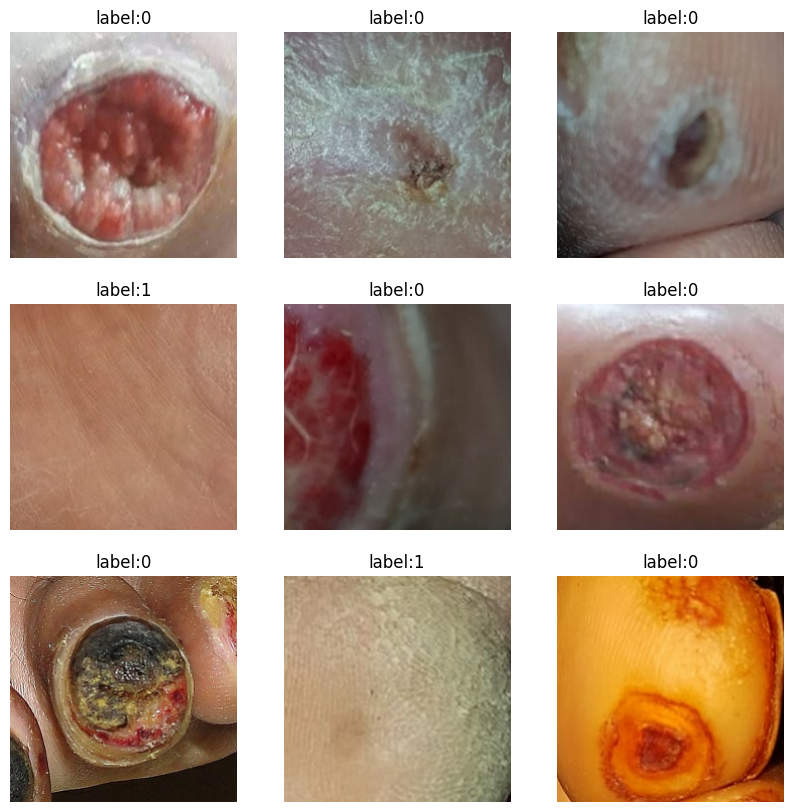

In [42]:
for image ,labels in train_ds.take(1):
    plt.figure(figsize=(10,10))
    for i in range(9):
        ax=plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(f'label:{labels[i].numpy()}')
        plt.axis("off")
    plt.show()

In [25]:
for image ,labels in train_ds.take(1):
    print(
        f" image shape : {image.shape}"
    )
    print(f"labels : {labels.shape}")
    print(f"labels : {labels.numpy()}")


 image shape : (32, 225, 225, 3)
labels : (32,)
labels : [1 1 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 1 1 0 1 0 0 1 1 0 1 0 1 1 0]


In [26]:
class_name=train_ds.class_names
print(class_name)

['Abnormal(Ulcer)', 'Normal(Healthy skin)']


In [35]:
## انا بزودهنا  في عدد الصور هنا عشان الموديل يقدي يدرب غلي صور كتير 
img_aumentation=Sequential(
    [
        layers.RandomRotation(factor=0.15),
        layers.RandomTranslation(height_factor=0.1,width_factor=0.1),
        layers.RandomFlip(),
        layers.GaussianNoise(stddev=0.09),
        layers.RandomContrast(factor=0.1),
       

    ],
    name="img_augmentation")


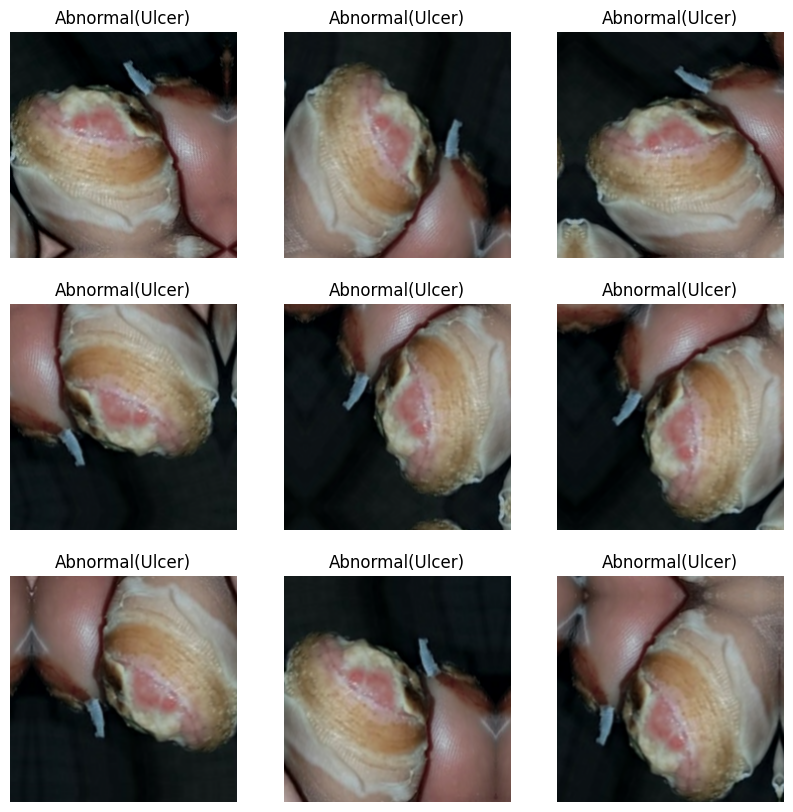

In [43]:
plt.figure(figsize=(10,10))
for image,labels in train_ds.take(1):
    for i in range(9):
        ax= plt.subplot(3,3,i+1)
        aug_img = img_aumentation(tf.expand_dims(image[0],axis=0))
        plt.imshow(aug_img[0].numpy().astype('uint8'))
        plt.title(class_name[labels[0]])
        plt.axis('off')

In [46]:
## دي طريقه عشان طريقه الرن تبقي سريعه 
AUTOTUNE=tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)

val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [81]:
## هنا عشان لو الموديل متحسنش توقف الموديل ى
lr_callback=callbacks.ReduceLROnPlateau(monitor= 'val_accuracy',factor=0.1,patience=8)## هنا لو accurcyمتحسنش بعد تمن محلاولات وقف المودل
stop_callbacks= callbacks.EarlyStopping(monitor= 'val_accuracy',patience=10)
model_ckp = callbacks.ModelCheckpoint('cnn.best_weight.h5',save_best_only=True,monitor='val_accuracy',mode='max')## هنا بيديني افضل عرض لي الصوره عندما تكون احسن ناتج مع الموديل


In [63]:
![image.png](attachment:image.png)

'[image.png]' is not recognized as an internal or external command,
operable program or batch file.


In [75]:

def cnn_buld(input_shape=(225,225,3),num_classes=2):
   
    model=Sequential([
        Input(shape=input_shape),
        img_aumentation,
        layers.Rescaling(1/255),
        Conv2D(64,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),
        
        Conv2D(128,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(256,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(256,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(512,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(512,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),

        
        Conv2D(512,(3,3),activation='relu',padding='same'),
        ReLU(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(512,(3,3),activation='relu',padding='same'),
        ReLU(),
        


        Flatten(),
        Dense(4096,activation='relu'),
        Dropout(0.5),
       Dense(num_classes, activation="softmax")



        


        

        

        


    ])
    optimizer= optimizers.Adam(learning_rate= 1e-3)
    loss = losses.SparseCategoricalCrossentropy() 
    model.compile(optimizer=optimizer,loss=loss,metrics=['accuracy'])
    model.summary()
    return model

cnn =cnn_buld()
print(cnn)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img_augmentation (Sequential)   │ (None, 225, 225, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_11 (Rescaling)        │ (None, 225, 225, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 225, 225, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_32 (ReLU)                 │ (None, 225, 225, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_33 (ReLU)                 │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_34 (ReLU)                 │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_35 (ReLU)                 │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 14, 14, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_36 (ReLU)                 │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_37 (ReLU)                 │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_38 (ReLU)                 │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 1, 1, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_39 (ReLU)                 │ (None, 1, 1, 512)      │             

 Total params: 11,329,922 (43.22 MB)

 Trainable params: 11,329,922 (43.22 MB)

 Non-trainable params: 0 (0.00 B)

<Sequential name=sequential_4, built=True>


In [82]:
history=cnn.fit(
    train_ds,
    validation_data=val_ds,
    callbacks=[lr_callback,stop_callbacks,model_ckp],
    epochs=epochs,
    verbose=1
)

Epoch 1/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8128 - loss: 0.4608

27/27 ━━━━━━━━━━━━━━━━━━━━ 106s 4s/step - accuracy: 0.8128 - loss: 0.4608 - val_accuracy: 0.7773 - val_loss: 0.5043 - learning_rate: 0.0010
Epoch 2/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8353 - loss: 0.4067

27/27 ━━━━━━━━━━━━━━━━━━━━ 110s 4s/step - accuracy: 0.8353 - loss: 0.4067 - val_accuracy: 0.8009 - val_loss: 0.4851 - learning_rate: 0.0010
Epoch 3/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8531 - loss: 0.4045

27/27 ━━━━━━━━━━━━━━━━━━━━ 107s 4s/step - accuracy: 0.8531 - loss: 0.4045 - val_accuracy: 0.8294 - val_loss: 0.4152 - learning_rate: 0.0010
Epoch 4/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 101s 4s/step - accuracy: 0.8697 - loss: 0.3485 - val_accuracy: 0.8246 - val_loss: 0.4087 - learning_rate: 0.0010
Epoch 5/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9135 - loss: 0.2485

27/27 ━━━━━━━━━━━━━━━━━━━━ 101s 4s/step - accuracy: 0.9135 - loss: 0.2485 - val_accuracy: 0.9289 - val_loss: 0.2317 - learning_rate: 0.0010
Epoch 6/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 96s 4s/step - accuracy: 0.9052 - loss: 0.2420 - val_accuracy: 0.8863 - val_loss: 0.2738 - learning_rate: 0.0010
Epoch 7/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 96s 4s/step - accuracy: 0.9301 - loss: 0.2261 - val_accuracy: 0.9242 - val_loss: 0.1913 - learning_rate: 0.0010
Epoch 8/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9479 - loss: 0.1454

27/27 ━━━━━━━━━━━━━━━━━━━━ 3660s 141s/step - accuracy: 0.9479 - loss: 0.1454 - val_accuracy: 0.9431 - val_loss: 0.1893 - learning_rate: 0.0010
Epoch 9/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 103s 4s/step - accuracy: 0.9727 - loss: 0.1049 - val_accuracy: 0.9384 - val_loss: 0.2001 - learning_rate: 0.0010
Epoch 10/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9585 - loss: 0.1081

27/27 ━━━━━━━━━━━━━━━━━━━━ 94s 3s/step - accuracy: 0.9585 - loss: 0.1081 - val_accuracy: 0.9621 - val_loss: 0.1314 - learning_rate: 0.0010
Epoch 11/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 107s 4s/step - accuracy: 0.9301 - loss: 0.1922 - val_accuracy: 0.9336 - val_loss: 0.1784 - learning_rate: 0.0010
Epoch 12/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 98s 4s/step - accuracy: 0.9372 - loss: 0.1577 - val_accuracy: 0.7109 - val_loss: 0.4704 - learning_rate: 0.0010
Epoch 13/200
27/27 ━━━━━━━━━━━━━━━━━━━━ 112s 4s/step - accuracy: 0.9289 - loss: 0.1744 - val_accuracy: 0.9384 - val_loss: 0.1614 - learning_rate: 0.0010
Epoch 14/200
14/27 ━━━━━━━━━━━━━━━━━━━━ 47s 4s/step - accuracy: 0.9353 - loss: 0.1797

KeyboardInterrupt: 

In [ ]:
y_test=[]
y_pred=[]
for image,labels in val_ds:
    pred = cnn.predict(image)
    preds=np.argmax(pred,axis=1)
    y_pred.extend(preds)
    y_test.extend(labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 834ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 573ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 552ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 550ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 553ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step


<function matplotlib.pyplot.show(close=None, block=None)>

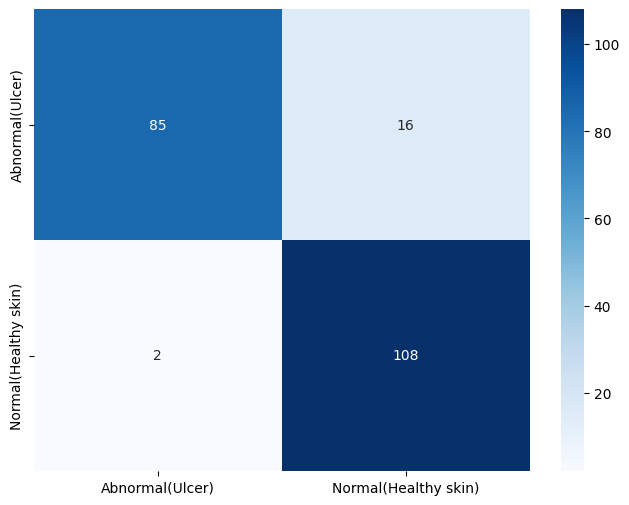

In [84]:
con=confusion_matrix(y_test,y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(con,annot=True,fmt="d",cmap="Blues",yticklabels=class_name,xticklabels=class_name)
plt.show

In [91]:

cnn.save("ulcer_classification.keras")


